In [54]:

import sys
from pathlib import Path

# Add the project root to Python's import path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import the reusable inference function
from src.stress_inference import predict_stress_window, FEATURE_COLUMNS

# Test it with one existing feature window
sample_features = df[FEATURE_COLUMNS].iloc[10].to_dict()
result = predict_stress_window(sample_features)

print("Inference module imported successfully.")
print("Number of features:", len(FEATURE_COLUMNS))
print("Prediction:", result)


Inference module imported successfully.
Number of features: 15
Prediction: {'predicted_class': 0, 'predicted_label': 'Low stress', 'elevated_stress_probability': 0.386}


In [53]:

from pathlib import Path

project_root = Path.cwd().parent
src_dir = project_root / "src"
src_dir.mkdir(parents=True, exist_ok=True)

module_code = '''from pathlib import Path

import joblib
import numpy as np
import pandas as pd


PROJECT_ROOT = Path(__file__).resolve().parents[1]
MODEL_PATH = PROJECT_ROOT / "models" / "stress_baseline.joblib"

_artifact = joblib.load(MODEL_PATH)
_model = _artifact["model"]
FEATURE_COLUMNS = _artifact["feature_columns"]


def predict_stress_window(window_features):
    """
    Predict a stress class from one window of physiological features.

    This is a research prototype, not a medical assessment.
    """
    window = pd.DataFrame([window_features])
    window = window.reindex(columns=FEATURE_COLUMNS)
    window = window.replace([np.inf, -np.inf], np.nan)

    prediction = int(_model.predict(window)[0])
    probabilities = _model.predict_proba(window)[0]
    classes = list(_model.classes_)

    elevated_probability = float(
        probabilities[classes.index(1)]
    )

    return {
        "predicted_class": prediction,
        "predicted_label": (
            "Elevated stress" if prediction == 1 else "Low stress"
        ),
        "elevated_stress_probability": round(
            elevated_probability, 3
        ),
    }
'''

module_path = src_dir / "stress_inference.py"
module_path.write_text(module_code, encoding="utf-8")

print("Created:", module_path)
print("Exists:", module_path.exists())
print("Model file exists:", (project_root / "models" / "stress_baseline.joblib").exists())


Created: /Users/varsha/Desktop/soldier-health-ai/src/stress_inference.py
Exists: True
Model file exists: True


In [49]:

import joblib
import pandas as pd
import numpy as np

artifact = joblib.load("../models/stress_baseline.joblib")
model = artifact["model"]
feature_columns = artifact["feature_columns"]

def predict_stress_window(window_features):
    """
    Predict a stress class from one window of physiological features.
    This is a research prototype, not a medical assessment.
    """
    window = pd.DataFrame([window_features])

    # Ensure the exact feature order used during training
    window = window.reindex(columns=feature_columns)
    window = window.replace([np.inf, -np.inf], np.nan)

    prediction = int(model.predict(window)[0])

    probabilities = model.predict_proba(window)[0]
    classes = list(model.classes_)
    elevated_index = classes.index(1)
    elevated_probability = float(probabilities[elevated_index])

    return {
        "predicted_class": prediction,
        "predicted_label": (
            "Elevated stress" if prediction == 1 else "Low stress"
        ),
        "elevated_stress_probability": round(elevated_probability, 3)
    }

# Test the function using an existing feature window
sample_features = df[feature_columns].iloc[10].to_dict()
result = predict_stress_window(sample_features)

print("Inference test result:")
print(result)


Inference test result:
{'predicted_class': 0, 'predicted_label': 'Low stress', 'elevated_stress_probability': 0.386}


In [48]:
from pathlib import Path

summary_path = Path("../data/processed/model_evaluation_summary.txt")

if summary_path.exists():
    print(summary_path.read_text())
else:
    print("Evaluation summary file not found.")

MODEL EVALUATION SUMMARY

Project:
5G-Enabled Edge-AI Wearable System for Predictive
Soldier Healthcare in Harsh Environments

Dataset:
Labelled wearable stress windows from a controlled
stress and structured-exercise dataset.

Model comparison:
- Physiology-only model:
  Accuracy = 0.488
  Balanced accuracy = 0.477
  Elevated-stress F1 = 0.562

- Physiology + HRV model:
  Accuracy = 0.444
  Balanced accuracy = 0.420
  Elevated-stress F1 = 0.538

HRV coverage:
- Usable HRV in 207 of 401 labelled windows (51.6%).
- Low-stress windows with HRV: 76 of 163 (46.6%).
- Elevated-stress windows with HRV: 131 of 238 (55.0%).

Conclusion:
Adding HRV did not improve the evaluated metrics.
The physiology-only model is retained as the current
baseline. Both models have limited performance and
require further validation before practical use.

Limitations:
- The dataset represents controlled activities, not
  soldiers in harsh operational environments.
- HRV is unavailable for approximately half of t

In [47]:

import pandas as pd
import numpy as np
import joblib

artifact = joblib.load("../models/stress_baseline.joblib")
model = artifact["model"]
feature_columns = artifact["feature_columns"]

# Select 5 low-stress and 5 elevated-stress windows
low = df[df["stress_class"] == 0].head(5)
elevated = df[df["stress_class"] == 1].head(5)
sample = pd.concat([low, elevated])

X_sample = sample[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

predictions = model.predict(X_sample)

results = pd.DataFrame({
    "Actual": sample["stress_class"].map({
        0: "Low stress",
        1: "Elevated stress"
    }).values,
    "Predicted": pd.Series(predictions, index=sample.index).map({
        0: "Low stress",
        1: "Elevated stress"
    }).values
})

display(results)
print("Sample accuracy:", round(
    (results["Actual"] == results["Predicted"]).mean(), 3
))


,Actual,Predicted
0,Low stress,Low stress
1,Low stress,Low stress
2,Low stress,Low stress
3,Low stress,Low stress
4,Low stress,Low stress
5,Elevated stress,Low stress
6,Elevated stress,Low stress
7,Elevated stress,Low stress
8,Elevated stress,Low stress
9,Elevated stress,Elevated stress


Sample accuracy: 0.6


In [46]:

import joblib
import pandas as pd
import numpy as np

# Load the saved artifact
artifact = joblib.load("../models/stress_baseline.joblib")

model = artifact["model"]
feature_columns = artifact["feature_columns"]

# Prepare five sample windows
X_sample = df[feature_columns].copy()
X_sample = X_sample.head(5)
X_sample = X_sample.replace([np.inf, -np.inf], np.nan)

# Predict stress classes
predictions = model.predict(X_sample)

results = pd.DataFrame({
    "Actual stress class": df["stress_class"].head(5).values,
    "Predicted stress class": predictions
})

results["Actual label"] = results["Actual stress class"].map({
    0: "Low stress",
    1: "Elevated stress"
})

results["Predicted label"] = results["Predicted stress class"].map({
    0: "Low stress",
    1: "Elevated stress"
})

print("Saved model loaded and predictions completed.")
print("Model type:", artifact["model_type"])
print("Stress threshold:", artifact["stress_threshold"])
display(results)


Saved model loaded and predictions completed.
Model type: physiology_only_baseline
Stress threshold: 5


,Actual stress class,Predicted stress class,Actual label,Predicted label
0,0,0,Low stress,Low stress
1,0,0,Low stress,Low stress
2,0,0,Low stress,Low stress
3,0,0,Low stress,Low stress
4,0,0,Low stress,Low stress


In [45]:
import joblib

saved_artifact = joblib.load("../models/stress_baseline.joblib")

print("Saved object type:", type(saved_artifact))

if isinstance(saved_artifact, dict):
    print("\nKeys in saved artifact:")
    for key, value in saved_artifact.items():
        print(f"{key}: {type(value)}")
else:
    print("Object has a predict method:", hasattr(saved_artifact, "predict"))

Saved object type: <class 'dict'>

Keys in saved artifact:
model: <class 'sklearn.pipeline.Pipeline'>
feature_columns: <class 'list'>
stress_threshold: <class 'int'>
model_type: <class 'str'>


In [43]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Load all labelled windows
df = pd.read_csv("../data/processed/labeled_stress_windows.csv")
df["stress_class"] = (df["self_reported_stress"] >= 5).astype(int)

# Physiological features only; no HRV or protocol-stage leakage
feature_columns = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

X = df[feature_columns].replace([np.inf, -np.inf], np.nan)
y = df["stress_class"]

# Train the baseline model
final_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

final_model.fit(X, y)

# Save model and its feature-column order
output_dir = Path("../models")
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": final_model,
        "feature_columns": feature_columns,
        "stress_threshold": 5,
        "model_type": "physiology_only_baseline"
    },
    output_dir / "stress_baseline.joblib"
)

print("Training windows:", len(X))
print("Features:", len(feature_columns))
print("Saved model:", output_dir / "stress_baseline.joblib")
print("Note: This is a research prototype, not a validated medical model.")

Training windows: 401
Features: 15
Saved model: ../models/stress_baseline.joblib
Note: This is a research prototype, not a validated medical model.


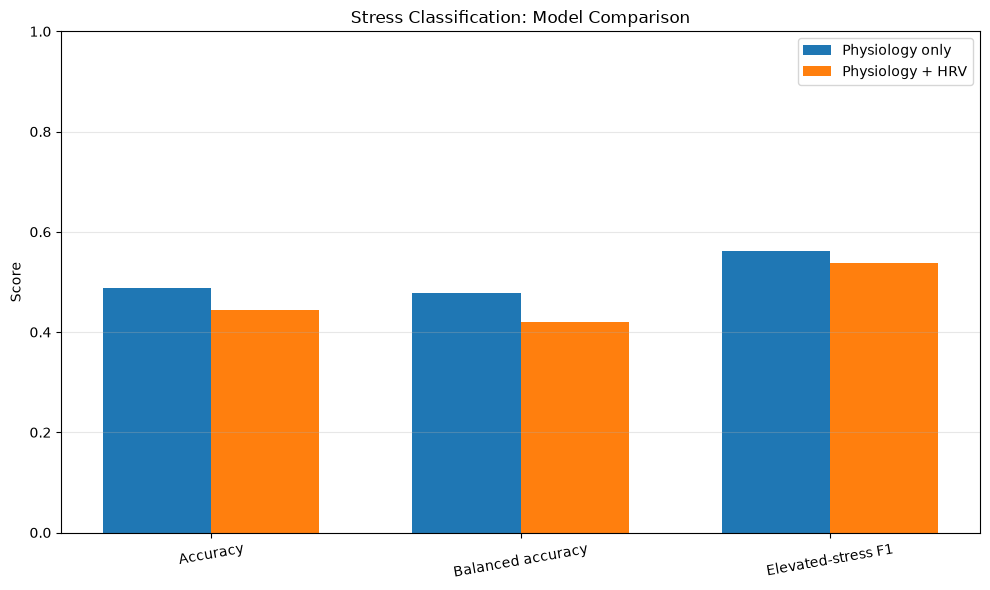

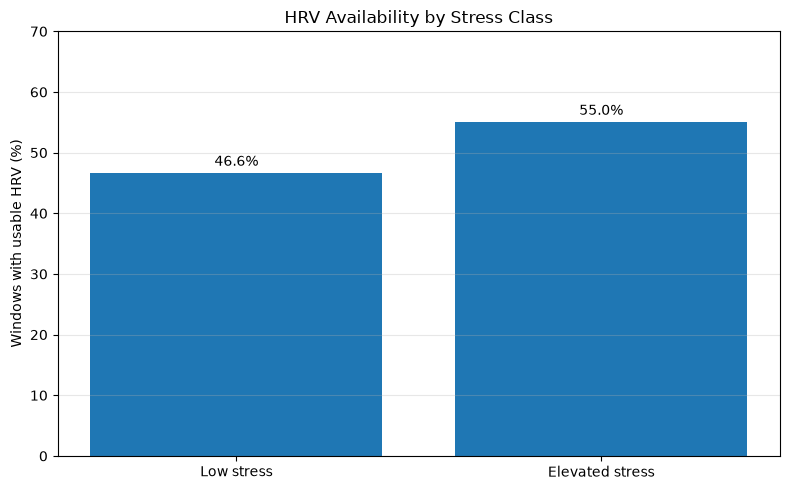

Graphs saved to:
../reports/figures/model_comparison.png
../reports/figures/hrv_availability.png


In [42]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the results already saved
results_dir = Path("../data/processed")
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

model_results = pd.read_csv(
    results_dir / "model_comparison_hrv.csv"
)

hrv_results = pd.read_csv(
    results_dir / "hrv_availability_by_stress.csv"
)

# Graph 1: Compare the two models
metrics = [
    "Accuracy",
    "Balanced accuracy",
    "Elevated-stress F1"
]

x = range(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    [i - width / 2 for i in x],
    [model_results.loc[0, m] for m in metrics],
    width,
    label="Physiology only"
)

ax.bar(
    [i + width / 2 for i in x],
    [model_results.loc[1, m] for m in metrics],
    width,
    label="Physiology + HRV"
)

ax.set_xticks(list(x))
ax.set_xticklabels(metrics, rotation=10)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Stress Classification: Model Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()

fig.savefig(
    figures_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Graph 2: HRV availability by stress class
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    hrv_results["Stress class"],
    hrv_results["Availability (%)"]
)

ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 70)
ax.set_ylabel("Windows with usable HRV (%)")
ax.set_title("HRV Availability by Stress Class")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()

fig.savefig(
    figures_dir / "hrv_availability.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Graphs saved to:")
print(figures_dir / "model_comparison.png")
print(figures_dir / "hrv_availability.png")


In [41]:
import pandas as pd
from pathlib import Path

# Save results inside the project's processed-data folder
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Model comparison using the same 207 windows
model_results = pd.DataFrame({
    "Model": [
        "Physiology only",
        "Physiology + HRV"
    ],
    "Evaluation windows": [207, 207],
    "Participants": [29, 29],
    "Accuracy": [0.488, 0.444],
    "Balanced accuracy": [0.477, 0.420],
    "Elevated-stress F1": [0.562, 0.538]
})

print("MODEL COMPARISON")
display(model_results.round(3))

model_results.to_csv(
    output_dir / "model_comparison_hrv.csv",
    index=False
)

# 2. HRV data availability
hrv_availability = pd.DataFrame({
    "Stress class": ["Low stress", "Elevated stress"],
    "Total windows": [163, 238],
    "Windows with HRV": [76, 131],
    "Availability (%)": [46.6, 55.0]
})

print("\nHRV AVAILABILITY BY STRESS CLASS")
display(hrv_availability)

hrv_availability.to_csv(
    output_dir / "hrv_availability_by_stress.csv",
    index=False
)

# 3. Write a concise report
report = """
MODEL EVALUATION SUMMARY
========================

Project:
5G-Enabled Edge-AI Wearable System for Predictive
Soldier Healthcare in Harsh Environments

Dataset:
Labelled wearable stress windows from a controlled
stress and structured-exercise dataset.

Model comparison:
- Physiology-only model:
  Accuracy = 0.488
  Balanced accuracy = 0.477
  Elevated-stress F1 = 0.562

- Physiology + HRV model:
  Accuracy = 0.444
  Balanced accuracy = 0.420
  Elevated-stress F1 = 0.538

HRV coverage:
- Usable HRV in 207 of 401 labelled windows (51.6%).
- Low-stress windows with HRV: 76 of 163 (46.6%).
- Elevated-stress windows with HRV: 131 of 238 (55.0%).

Conclusion:
Adding HRV did not improve the evaluated metrics.
The physiology-only model is retained as the current
baseline. Both models have limited performance and
require further validation before practical use.

Limitations:
- The dataset represents controlled activities, not
  soldiers in harsh operational environments.
- HRV is unavailable for approximately half of the
  labelled windows.
- These results do not establish clinical validity
  or reliable real-world stress prediction.
"""

report_path = output_dir / "model_evaluation_summary.txt"
report_path.write_text(report.strip(), encoding="utf-8")

print("\nSaved files:")
print(output_dir / "model_comparison_hrv.csv")
print(output_dir / "hrv_availability_by_stress.csv")
print(report_path)

MODEL COMPARISON


,Model,Evaluation windows,Participants,Accuracy,Balanced accuracy,Elevated-stress F1
0,Physiology only,207,29,0.488,0.477,0.562
1,Physiology + HRV,207,29,0.444,0.420,0.538



HRV AVAILABILITY BY STRESS CLASS


,Stress class,Total windows,Windows with HRV,Availability (%)
0,Low stress,163,76,46.6
1,Elevated stress,238,131,55.0



Saved files:
../data/processed/model_comparison_hrv.csv
../data/processed/hrv_availability_by_stress.csv
../data/processed/model_evaluation_summary.txt


In [40]:
import pandas as pd

# Load all labelled windows, including those without HRV
df_audit = pd.read_csv(
    "../data/processed/labeled_stress_windows_with_hrv.csv"
)

df_audit["stress_class"] = (
    df_audit["self_reported_stress"] >= 5
).astype(int)

df_audit["hrv_available"] = (
    df_audit["hrv_rmssd_ms"].notna()
    & df_audit["hrv_sdnn_ms"].notna()
)

print("HRV availability by stress class:")
print(
    df_audit.groupby("stress_class")["hrv_available"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "total_windows",
        "sum": "windows_with_hrv",
        "mean": "availability_fraction"
    })
    .round(3)
)

print("\nHRV availability by protocol stage:")
print(
    df_audit.groupby("protocol_stage")["hrv_available"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "total_windows",
        "sum": "windows_with_hrv",
        "mean": "availability_fraction"
    })
    .round(3)
)

print("\nOverall HRV coverage:")
print(
    f"{df_audit['hrv_available'].sum()} / {len(df_audit)} "
    f"({100 * df_audit['hrv_available'].mean():.1f}%)"
)

HRV availability by stress class:
              total_windows  windows_with_hrv  availability_fraction
stress_class                                                        
0                       163                76                  0.466
1                       238               131                  0.550

HRV availability by protocol stage:
                  total_windows  windows_with_hrv  availability_fraction
protocol_stage                                                          
Opposite Opinion             36                 8                  0.222
Real Opinion                 37                 8                  0.216
Stroop                       61                33                  0.541
Subtract                     42                15                  0.357
TMCT                        225               143                  0.636

Overall HRV coverage:
207 / 401 (51.6%)


In [39]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load labelled data with HRV features
df_hrv = pd.read_csv(
    "../data/processed/labeled_stress_windows_with_hrv.csv"
)

# Create the binary target
df_hrv["stress_class"] = (
    df_hrv["self_reported_stress"] >= 5
).astype(int)

# Use only rows where BOTH HRV features are available.
# Both models will use exactly these same rows.
evaluation_df = df_hrv.dropna(
    subset=["hrv_rmssd_ms", "hrv_sdnn_ms"]
).copy()

# Original physiological features
physiology_features = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

# Ensure all required columns are available
required = (
    physiology_features
    + ["hrv_rmssd_ms", "hrv_sdnn_ms",
       "stress_class", "subject_id"]
)

missing = [c for c in required if c not in evaluation_df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Inputs, target, and participant groups
X_base = evaluation_df[physiology_features].replace(
    [np.inf, -np.inf], np.nan
)

X_hrv = evaluation_df[
    physiology_features + ["hrv_rmssd_ms", "hrv_sdnn_ms"]
].replace([np.inf, -np.inf], np.nan)

y = evaluation_df["stress_class"]
groups = evaluation_df["subject_id"]

# Five-fold grouped validation
n_groups = groups.nunique()
if n_groups < 5:
    raise ValueError(
        f"Need at least 5 participants; found {n_groups}."
    )

cv = GroupKFold(n_splits=5)

models = {
    "Physiology only": X_base,
    "Physiology + HRV": X_hrv
}

results = []
predictions = {}

for model_name, X in models.items():
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )

    y_pred = cross_val_predict(
        model, X, y,
        groups=groups,
        cv=cv,
        method="predict"
    )

    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Windows": len(y),
        "Participants": n_groups,
        "Accuracy": accuracy_score(y, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y, y_pred),
        "Elevated-stress F1": f1_score(y, y_pred, zero_division=0)
    })

print("Evaluation windows:", len(evaluation_df))
print("Participants:", n_groups)
print("\nModel comparison:")
print(
    pd.DataFrame(results).round(3).to_string(index=False)
)

# Detailed results for the model with HRV
best_name = "Physiology + HRV"
y_pred = predictions[best_name]

print("\nPhysiology + HRV classification report:")
print(classification_report(
    y, y_pred,
    labels=[0, 1],
    target_names=["Low stress", "Elevated stress"],
    zero_division=0
))

print("Confusion matrix (rows=actual, columns=predicted):")
print(confusion_matrix(y, y_pred, labels=[0, 1]))

Evaluation windows: 207
Participants: 29

Model comparison:
           Model  Windows  Participants  Accuracy  Balanced accuracy  Elevated-stress F1
 Physiology only      207            29     0.488              0.477               0.562
Physiology + HRV      207            29     0.444              0.420               0.538

Physiology + HRV classification report:
                 precision    recall  f1-score   support

     Low stress       0.28      0.33      0.30        76
Elevated stress       0.57      0.51      0.54       131

       accuracy                           0.44       207
      macro avg       0.42      0.42      0.42       207
   weighted avg       0.46      0.44      0.45       207

Confusion matrix (rows=actual, columns=predicted):
[[25 51]
 [64 67]]


In [37]:

stage_participant_summary = (
    high_confidence_df
    .groupby("protocol_stage")
    .agg(
        windows=("stress_class", "size"),
        participants=("subject_id", "nunique"),
        low_stress=("stress_class", lambda x: (x == 0).sum()),
        elevated_stress=("stress_class", lambda x: (x == 1).sum())
    )
    .reset_index()
)

display(stage_participant_summary)


,protocol_stage,windows,participants,low_stress,elevated_stress
0,Opposite Opinion,21,21,12,9
1,Real Opinion,21,21,15,6
2,Stroop,54,17,34,20
3,Subtract,21,20,9,12
4,TMCT,212,33,57,155


In [36]:

stage_summary = (
    high_confidence_df
    .groupby("protocol_stage")
    .agg(
        windows=("stress_class", "size"),
        elevated_windows=("stress_class", "sum"),
        mean_stress_label=("self_reported_stress", "mean")
    )
    .reset_index()
)

stage_summary["elevated_percentage"] = (
    100 * stage_summary["elevated_windows"]
    / stage_summary["windows"]
).round(1)

display(
    stage_summary.sort_values(
        "elevated_percentage", ascending=False
    ).round(2)
)


,protocol_stage,windows,elevated_windows,mean_stress_label,elevated_percentage
4,TMCT,212,155,5.98,73.1
3,Subtract,21,12,4.45,57.1
0,Opposite Opinion,21,9,4.38,42.9
2,Stroop,54,20,4.10,37.0
1,Real Opinion,21,6,3.62,28.6


In [35]:

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

eval_df = high_confidence_df.copy()
X = eval_df[numeric_features].apply(
    pd.to_numeric, errors="coerce"
)
y = eval_df["stress_class"].astype(int)
groups = eval_df["subject_id"].astype(str)

phys_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

predictions = cross_val_predict(
    phys_model,
    X,
    y,
    groups=groups,
    cv=GroupKFold(n_splits=5)
)

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y, predictions, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y,
    predictions,
    labels=[0, 1],
    target_names=["Low stress", "Elevated stress"],
    zero_division=0
))


Confusion matrix (rows = actual, columns = predicted):
[[ 52  75]
 [101 101]]

Classification report:
                 precision    recall  f1-score   support

     Low stress       0.34      0.41      0.37       127
Elevated stress       0.57      0.50      0.53       202

       accuracy                           0.47       329
      macro avg       0.46      0.45      0.45       329
   weighted avg       0.48      0.47      0.47       329



In [34]:

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

# Use only windows with at least 80% label overlap
eval_df = high_confidence_df.copy()

numeric_features = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

eval_df[numeric_features] = eval_df[numeric_features].apply(
    pd.to_numeric, errors="coerce"
)

X_phys = eval_df[numeric_features]
X_stage = eval_df[["protocol_stage"]]
X_both = eval_df[numeric_features + ["protocol_stage"]]

y = eval_df["stress_class"].astype(int)
groups = eval_df["subject_id"].astype(str)
cv = GroupKFold(n_splits=5)

def physiology_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])

def stage_model():
    return Pipeline([
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])

def combined_model():
    preprocessing = ColumnTransformer([
        ("physiology", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("stage", OneHotEncoder(handle_unknown="ignore"),
         ["protocol_stage"])
    ])

    return Pipeline([
        ("preprocessor", preprocessing),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])

experiments = [
    ("Majority baseline", DummyClassifier(strategy="most_frequent"), X_phys),
    ("Physiology only", physiology_model(), X_phys),
    ("Stage only", stage_model(), X_stage),
    ("Physiology + stage", combined_model(), X_both)
]

results = []

for name, estimator, X in experiments:
    predictions = cross_val_predict(
        estimator, X, y, groups=groups, cv=cv
    )

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y, predictions), 3),
        "Balanced accuracy": round(
            balanced_accuracy_score(y, predictions), 3
        ),
        "Elevated-stress F1": round(
            f1_score(y, predictions, pos_label=1, zero_division=0), 3
        )
    })

display(
    pd.DataFrame(results)
    .sort_values("Balanced accuracy", ascending=False)
    .reset_index(drop=True)
)


,Model,Accuracy,Balanced accuracy,Elevated-stress F1
0,Stage only,0.684,0.659,0.749
1,Physiology + stage,0.562,0.544,0.636
2,Majority baseline,0.614,0.500,0.761
3,Physiology only,0.465,0.455,0.534


In [33]:
 
# Keep windows with at least 80% overlap with their label interval
high_confidence_df = model_df[
    model_df["overlap_fraction"] >= 0.80
].copy()

print("Original windows:", len(model_df))
print("High-confidence windows:", len(high_confidence_df))
print("Windows excluded:", len(model_df) - len(high_confidence_df))

print("\nClass distribution in high-confidence subset:")
display(
    high_confidence_df["stress_class"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Low stress", 1: "Elevated stress"})
    .to_frame("count")
)

print("\nParticipants remaining:", high_confidence_df["subject_id"].nunique())
print("\nParticipants represented in both classes:")
print(
    high_confidence_df.groupby("subject_id")["stress_class"]
    .nunique()
    .eq(2)
    .sum()
)


Original windows: 401
High-confidence windows: 329
Windows excluded: 72

Class distribution in high-confidence subset:


,count
stress_class,
Low stress,127
Elevated stress,202



Participants remaining: 33

Participants represented in both classes:
15


In [32]:

print("Overlap fraction summary:")
display(model_df["overlap_fraction"].describe())

print("\nOverlap fraction by stress class:")
display(
    model_df.groupby("stress_class")["overlap_fraction"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

print("\nWindows with less than 80% overlap:")
print(
    (model_df["overlap_fraction"] < 0.80).sum(),
    "out of",
    len(model_df)
)


Overlap fraction summary:


count    401.000000
mean       0.914381
std        0.152118
min        0.500000
25%        0.900000
50%        1.000000
75%        1.000000
max        1.000000
Name: overlap_fraction, dtype: float64


Overlap fraction by stress class:


,count,mean,median,min,max
stress_class,,,,,
0,163,0.896,1.0,0.5,1.0
1,238,0.927,1.0,0.5,1.0



Windows with less than 80% overlap:
72 out of 401


In [31]:

participant_summary = (
    model_df.groupby("subject_id")
    .agg(
        total_windows=("stress_class", "size"),
        low_stress=("stress_class", lambda x: (x == 0).sum()),
        elevated_stress=("stress_class", lambda x: (x == 1).sum())
    )
    .reset_index()
)

participant_summary["classes_present"] = (
    (participant_summary["low_stress"] > 0).astype(int)
    + (participant_summary["elevated_stress"] > 0).astype(int)
)

print("Number of participants:", len(participant_summary))
print("\nParticipants with both classes:")
print((participant_summary["classes_present"] == 2).sum())

display(
    participant_summary.sort_values(
        ["classes_present", "total_windows"],
        ascending=[True, False]
    )
)


Number of participants: 33

Participants with both classes:
16


,subject_id,total_windows,low_stress,elevated_stress,classes_present
9,S11,14,0,14,1
23,f08,14,14,0,1
20,f04,13,13,0,1
26,f11,13,0,13,1
30,f16,13,0,13,1
31,f17,13,0,13,1
3,S05,12,12,0,1
7,S09,12,0,12,1
12,S14,12,0,12,1
15,S17,12,12,0,1


In [30]:

import pandas as pd

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Use the existing labelled dataset
evaluation_df = model_df.dropna(
    subset=["subject_id", "stress_class", "protocol_stage"]
).copy()

numeric_features = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

# Ensure numeric features are numeric
evaluation_df[numeric_features] = evaluation_df[
    numeric_features
].apply(pd.to_numeric, errors="coerce")

X_phys = evaluation_df[numeric_features]
X_stage = evaluation_df[["protocol_stage"]]
X_both = evaluation_df[numeric_features + ["protocol_stage"]]

y = evaluation_df["stress_class"].astype(int)
groups = evaluation_df["subject_id"].astype(str)

cv = GroupKFold(n_splits=5)

def make_physiology_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])

def make_stage_model():
    return Pipeline([
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])

def make_combined_model():
    preprocessing = ColumnTransformer([
        ("physiology", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("stage", OneHotEncoder(handle_unknown="ignore"),
         ["protocol_stage"])
    ])

    return Pipeline([
        ("preprocessor", preprocessing),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])

experiments = [
    ("Majority baseline", DummyClassifier(strategy="most_frequent"),
     X_phys),
    ("Physiology only", make_physiology_model(), X_phys),
    ("Stage only", make_stage_model(), X_stage),
    ("Physiology + stage", make_combined_model(), X_both)
]

results = []

for name, estimator, X in experiments:
    predictions = cross_val_predict(
        estimator,
        X,
        y,
        groups=groups,
        cv=cv
    )

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y, predictions), 3),
        "Balanced accuracy": round(
            balanced_accuracy_score(y, predictions), 3
        ),
        "Elevated-stress F1": round(
            f1_score(y, predictions, pos_label=1, zero_division=0), 3
        )
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values(
    "Balanced accuracy", ascending=False
).reset_index(drop=True))


,Model,Accuracy,Balanced accuracy,Elevated-stress F1
0,Stage only,0.626,0.611,0.686
1,Physiology + stage,0.581,0.570,0.641
2,Physiology only,0.514,0.506,0.571
3,Majority baseline,0.594,0.500,0.745


In [29]:
for name in [
    "df", "labeled_df", "model_df",
    "X_train", "X_test", "y_train", "y_test",
    "X_cv", "y_cv", "groups_cv"
]:
    if name in globals():
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"{name}: shape={obj.shape}")
        else:
            print(f"{name}: available")
    else:
        print(f"{name}: NOT DEFINED")

df: shape=(401, 34)
labeled_df: shape=(401, 34)
model_df: shape=(401, 34)
X_train: shape=(308, 15)
X_test: shape=(93, 15)
y_train: shape=(308,)
y_test: shape=(93,)
X_cv: shape=(401, 15)
y_cv: shape=(401,)
groups_cv: shape=(401,)


In [28]:
import pandas as pd

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

feature_cols = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

numeric_cols = feature_cols
categorical_cols = ["protocol_stage"]

X_physiology = model_df[numeric_cols]
X_stage = model_df[categorical_cols]
X_combined = model_df[numeric_cols + categorical_cols]

y = model_df["stress_class"]
groups = model_df["subject_id"]

cv = GroupKFold(n_splits=5)

def make_numeric_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

def make_model(include_stage):
    transformers = [
        ("numeric", make_numeric_pipeline(), numeric_cols)
    ]

    if include_stage:
        transformers.append((
            "stage",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ))

    preprocessing = ColumnTransformer(transformers)

    return Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])

models = {
    "Physiology only": (
        X_physiology,
        make_model(include_stage=False)
    ),
    "Stage only": (
        X_stage,
        Pipeline([
            ("stage", OneHotEncoder(handle_unknown="ignore")),
            ("classifier", LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42
            ))
        ])
    ),
    "Physiology + stage": (
        X_combined,
        make_model(include_stage=True)
    )
}

results = []

for name, (X, estimator) in models.items():
    predictions = cross_val_predict(
        estimator,
        X,
        y,
        groups=groups,
        cv=cv
    )

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y, predictions), 3),
        "Balanced accuracy": round(
            balanced_accuracy_score(y, predictions), 3
        ),
        "Elevated-stress F1": round(
            f1_score(y, predictions, pos_label=1), 3
        )
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("Balanced accuracy", ascending=False))

,Model,Accuracy,Balanced accuracy,Elevated-stress F1
1,Stage only,0.626,0.611,0.686
2,Physiology + stage,0.581,0.570,0.641
0,Physiology only,0.514,0.506,0.571


In [27]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Input contains protocol stage only, not physiological features
X_stage = model_df[["protocol_stage"]]
y_stage = model_df["stress_class"]
groups_stage = model_df["subject_id"]

stage_model = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

cv_stage = GroupKFold(n_splits=5)

for name, estimator in [
    ("Majority baseline", DummyClassifier(strategy="most_frequent")),
    ("Protocol-stage-only model", stage_model)
]:
    predictions = cross_val_predict(
        estimator,
        X_stage,
        y_stage,
        groups=groups_stage,
        cv=cv_stage
    )

    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_stage, predictions), 3))
    print(
        "Balanced accuracy:",
        round(balanced_accuracy_score(y_stage, predictions), 3)
    )
    print(
        "Elevated-stress F1:",
        round(f1_score(y_stage, predictions, pos_label=1), 3)
    )


Majority baseline
Accuracy: 0.594
Balanced accuracy: 0.5
Elevated-stress F1: 0.745

Protocol-stage-only model
Accuracy: 0.626
Balanced accuracy: 0.611
Elevated-stress F1: 0.686


In [26]:
# Check how stress classes are distributed across protocol stages
print("Stress classes by protocol stage:")

display(
    pd.crosstab(
        model_df["protocol_stage"],
        model_df["stress_class"],
        margins=True
    )
)

print("\nStress-class percentages within each stage:")

stage_percentages = pd.crosstab(
    model_df["protocol_stage"],
    model_df["stress_class"],
    normalize="index"
).mul(100).round(1)

display(stage_percentages)

print("\nNumber of participants represented in each stage:")

display(
    model_df.groupby("protocol_stage")["subject_id"]
    .nunique()
    .sort_values(ascending=False)
)

Stress classes by protocol stage:


stress_class,0,1,All
protocol_stage,,,
Opposite Opinion,21,15,36
Real Opinion,22,15,37
Stroop,39,22,61
Subtract,17,25,42
TMCT,64,161,225
All,163,238,401



Stress-class percentages within each stage:


stress_class,0,1
protocol_stage,,
Opposite Opinion,58.3,41.7
Real Opinion,59.5,40.5
Stroop,63.9,36.1
Subtract,40.5,59.5
TMCT,28.4,71.6



Number of participants represented in each stage:


protocol_stage
Subtract            33
TMCT                33
Opposite Opinion    32
Real Opinion        32
Stroop              17
Name: subject_id, dtype: int64

In [25]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Use the 15 physiological features already selected
feature_cols = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

# Keep only participants who have both stress classes
classes_per_participant = (
    model_df.groupby("subject_id")["stress_class"].nunique()
)

mixed_subjects = classes_per_participant[
    classes_per_participant == 2
].index

mixed_df = model_df[
    model_df["subject_id"].isin(mixed_subjects)
].copy()

X = mixed_df[feature_cols]
y = mixed_df["stress_class"]
groups = mixed_df["subject_id"]

cv = GroupKFold(n_splits=5)

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])
}

for name, estimator in models.items():
    predictions = cross_val_predict(
        estimator,
        X,
        y,
        groups=groups,
        cv=cv
    )

    print(f"\n{'=' * 15} {name} {'=' * 15}")
    print("Accuracy:", round(accuracy_score(y, predictions), 3))
    print(
        "Balanced accuracy:",
        round(balanced_accuracy_score(y, predictions), 3)
    )
    print(
        "Elevated-stress F1:",
        round(f1_score(y, predictions, pos_label=1), 3)
    )
    print("\nClassification report:")
    print(classification_report(
        y,
        predictions,
        labels=[0, 1],
        target_names=["Low stress", "Elevated stress"],
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y, predictions, labels=[0, 1]))


=============== Majority baseline ===============
Accuracy: 0.656
Balanced accuracy: 0.5
Elevated-stress F1: 0.793

Classification report:
                 precision    recall  f1-score   support

     Low stress       0.00      0.00      0.00        67
Elevated stress       0.66      1.00      0.79       128

       accuracy                           0.66       195
      macro avg       0.33      0.50      0.40       195
   weighted avg       0.43      0.66      0.52       195

Confusion matrix:
[[  0  67]
 [  0 128]]

=============== Logistic Regression ===============
Accuracy: 0.569
Balanced accuracy: 0.565
Elevated-stress F1: 0.638

Classification report:
                 precision    recall  f1-score   support

     Low stress       0.41      0.55      0.47        67
Elevated stress       0.71      0.58      0.64       128

       accuracy                           0.57       195
      macro avg       0.56      0.57      0.55       195
   weighted avg       0.61      0.57      0

In [24]:
# Find participants who have both stress classes
classes_per_participant = (
    model_df.groupby("subject_id")["stress_class"].nunique()
)

mixed_subjects = classes_per_participant[
    classes_per_participant == 2
].index

mixed_df = model_df[
    model_df["subject_id"].isin(mixed_subjects)
].copy()

print("Total labeled windows:", len(model_df))
print("Participants in full dataset:", model_df["subject_id"].nunique())

print("\nParticipants with both stress classes:", len(mixed_subjects))
print("Windows from these participants:", len(mixed_df))

print("\nClass distribution in this subset:")
print(mixed_df["stress_class"].value_counts().sort_index())

print("\nWindows per participant and class:")
display(
    mixed_df.groupby(["subject_id", "stress_class"])
    .size()
    .unstack(fill_value=0)
)

Total labeled windows: 401
Participants in full dataset: 33

Participants with both stress classes: 16
Windows from these participants: 195

Class distribution in this subset:
stress_class
0     67
1    128
Name: count, dtype: int64

Windows per participant and class:


stress_class,0,1
subject_id,,
S01,8,4
S06,6,6
S08,4,5
S10,4,7
S13,6,5
S15,2,9
S16,6,5
S18,11,2
f01,3,15


In [23]:

# Check whether each participant has both stress classes
participant_summary = (
    model_df.groupby("subject_id")
    .agg(
        windows=("stress_class", "size"),
        unique_stress_classes=("stress_class", "nunique"),
        mean_stress_score=("self_reported_stress", "mean"),
        low_stress_windows=(
            "stress_class",
            lambda s: (s == 0).sum()
        ),
        elevated_stress_windows=(
            "stress_class",
            lambda s: (s == 1).sum()
        )
    )
    .sort_values("mean_stress_score")
)

print("Participants:", len(participant_summary))
print("\nParticipants with only one class:")
display(
    participant_summary[
        participant_summary["unique_stress_classes"] == 1
    ]
)

print("\nParticipant-level summary:")
display(participant_summary)

print("\nStress score by class:")
display(
    model_df.groupby("stress_class")["self_reported_stress"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)



Participants: 33

Participants with only one class:


,windows,unique_stress_classes,mean_stress_score,low_stress_windows,elevated_stress_windows
subject_id,,,,,
S17,12,1,1.500000,12,0
S04,11,1,2.272727,11,0
f08,14,1,2.500000,14,0
S05,12,1,3.000000,12,0
S03,11,1,3.363636,11,0
f06,12,1,3.583333,12,0
f05,11,1,3.727273,11,0
f04,13,1,3.846154,13,0
S09,12,1,5.416667,0,12



Participant-level summary:


,windows,unique_stress_classes,mean_stress_score,low_stress_windows,elevated_stress_windows
subject_id,,,,,
S17,12,1,1.500000,12,0
S04,11,1,2.272727,11,0
f08,14,1,2.500000,14,0
S05,12,1,3.000000,12,0
S03,11,1,3.363636,11,0
S18,13,2,3.384615,11,2
S08,9,2,3.555556,4,5
f06,12,1,3.583333,12,0
f05,11,1,3.727273,11,0



Stress score by class:


,count,mean,std,min,max
stress_class,,,,,
0,163,3.13,0.98,1.0,4.5
1,238,6.57,1.45,5.0,10.0


In [22]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

feature_cols = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

df_cv = model_df.dropna(
    subset=["subject_id", "stress_class"]
).copy()

X_cv = df_cv[feature_cols].apply(
    pd.to_numeric, errors="coerce"
)
y_cv = df_cv["stress_class"].astype(int)
groups_cv = df_cv["subject_id"]

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

cv = GroupKFold(n_splits=5)

y_true_all = []
y_pred_all = []

for train_idx, val_idx in cv.split(X_cv, y_cv, groups_cv):
    model_fold = clone(rf_model)

    model_fold.fit(
        X_cv.iloc[train_idx],
        y_cv.iloc[train_idx]
    )

    predictions = model_fold.predict(X_cv.iloc[val_idx])

    y_true_all.extend(y_cv.iloc[val_idx].tolist())
    y_pred_all.extend(predictions.tolist())

print("Random Forest — 5-fold participant-grouped evaluation")
print(
    "Accuracy:",
    round(accuracy_score(y_true_all, y_pred_all), 3)
)
print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_true_all, y_pred_all), 3)
)
print(
    "Elevated-stress F1:",
    round(f1_score(y_true_all, y_pred_all, zero_division=0), 3)
)

print("\nClassification report:")
print(classification_report(
    y_true_all,
    y_pred_all,
    labels=[0, 1],
    target_names=["Low stress", "Elevated stress"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_true_all, y_pred_all, labels=[0, 1]))


Random Forest — 5-fold participant-grouped evaluation
Accuracy: 0.469
Balanced accuracy: 0.462
Elevated-stress F1: 0.528

Classification report:
                 precision    recall  f1-score   support

     Low stress       0.37      0.42      0.39       163
Elevated stress       0.56      0.50      0.53       238

       accuracy                           0.47       401
      macro avg       0.46      0.46      0.46       401
   weighted avg       0.48      0.47      0.47       401

Confusion matrix:
[[ 69  94]
 [119 119]]


In [21]:

from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np

feature_cols = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

df_cv = model_df.dropna(
    subset=["subject_id", "stress_class"]
).copy()

X_cv = df_cv[feature_cols].apply(
    pd.to_numeric, errors="coerce"
)
y_cv = df_cv["stress_class"].astype(int)
groups_cv = df_cv["subject_id"]

models = {
    "Majority baseline": DummyClassifier(
        strategy="most_frequent"
    ),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])
}

cv = GroupKFold(n_splits=5)

for name, estimator in models.items():
    y_true_all = []
    y_pred_all = []

    for train_idx, val_idx in cv.split(X_cv, y_cv, groups_cv):
        model_fold = clone(estimator)

        model_fold.fit(
            X_cv.iloc[train_idx],
            y_cv.iloc[train_idx]
        )

        predictions = model_fold.predict(X_cv.iloc[val_idx])

        y_true_all.extend(y_cv.iloc[val_idx].tolist())
        y_pred_all.extend(predictions.tolist())

    print(f"\n{'=' * 15} {name} {'=' * 15}")
    print(
        "Balanced accuracy:",
        round(
            balanced_accuracy_score(y_true_all, y_pred_all),
            3
        )
    )
    print("\nClassification report:")
    print(classification_report(
        y_true_all,
        y_pred_all,
        labels=[0, 1],
        target_names=["Low stress", "Elevated stress"],
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(
        y_true_all, y_pred_all, labels=[0, 1]
    ))



=============== Majority baseline ===============
Balanced accuracy: 0.5

Classification report:
                 precision    recall  f1-score   support

     Low stress       0.00      0.00      0.00       163
Elevated stress       0.59      1.00      0.74       238

       accuracy                           0.59       401
      macro avg       0.30      0.50      0.37       401
   weighted avg       0.35      0.59      0.44       401

Confusion matrix:
[[  0 163]
 [  0 238]]

=============== Logistic Regression ===============
Balanced accuracy: 0.506

Classification report:
                 precision    recall  f1-score   support

     Low stress       0.41      0.47      0.44       163
Elevated stress       0.60      0.55      0.57       238

       accuracy                           0.51       401
      macro avg       0.51      0.51      0.50       401
   weighted avg       0.52      0.51      0.52       401

Confusion matrix:
[[ 76  87]
 [108 130]]


In [20]:

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

# Use the existing participant-labelled dataset
feature_cols = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

df_cv = model_df.dropna(
    subset=["subject_id", "stress_class"]
).copy()

X_cv = df_cv[feature_cols].apply(pd.to_numeric, errors="coerce")
y_cv = df_cv["stress_class"].astype(int)
groups_cv = df_cv["subject_id"]

cv = GroupKFold(n_splits=5)

models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])
}

results = []

for name, estimator in models.items():
    fold_accuracy = []
    fold_f1 = []

    for train_idx, val_idx in cv.split(X_cv, y_cv, groups_cv):
        X_train_cv = X_cv.iloc[train_idx]
        X_val_cv = X_cv.iloc[val_idx]
        y_train_cv = y_cv.iloc[train_idx]
        y_val_cv = y_cv.iloc[val_idx]

        estimator.fit(X_train_cv, y_train_cv)
        predictions = estimator.predict(X_val_cv)

        fold_accuracy.append(
            accuracy_score(y_val_cv, predictions)
        )
        fold_f1.append(
            f1_score(y_val_cv, predictions, zero_division=0)
        )

    results.append({
        "Model": name,
        "Mean CV Accuracy": np.mean(fold_accuracy),
        "Mean CV F1": np.mean(fold_f1)
    })

display(pd.DataFrame(results).round(3))


,Model,Mean CV Accuracy,Mean CV F1
0,Majority-class baseline,0.590,0.728
1,Logistic Regression,0.515,0.562


In [19]:

import numpy as np
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Use all labelled windows, with the existing 15 features
feature_cols = X_train.columns.tolist()
X_all = model_df[feature_cols]
y_all = model_df["stress_class"]
groups = model_df["subject_id"]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate predictions only when each participant is held out
oof_prob = np.full(len(model_df), np.nan)

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_all, y_all, groups=groups), start=1
):
    fold_model = clone(model)

    fold_model.fit(
        X_all.iloc[train_idx],
        y_all.iloc[train_idx]
    )

    oof_prob[val_idx] = fold_model.predict_proba(
        X_all.iloc[val_idx]
    )[:, 1]

    print(
        f"Fold {fold}: "
        f"{groups.iloc[train_idx].nunique()} training participants, "
        f"{groups.iloc[val_idx].nunique()} validation participants"
    )

# Evaluate out-of-fold predictions at the default threshold
oof_pred = (oof_prob >= 0.50).astype(int)

print("\n5-Fold Participant-Grouped Results")
print("Accuracy:", round(accuracy_score(y_all, oof_pred), 3))
print("Elevated-stress F1:", round(f1_score(y_all, oof_pred), 3))

print("\nClassification report:")
print(
    classification_report(
        y_all,
        oof_pred,
        labels=[0, 1],
        target_names=["Low stress", "Elevated stress"],
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_all, oof_pred, labels=[0, 1]))


Fold 1: 27 training participants, 6 validation participants
Fold 2: 27 training participants, 6 validation participants
Fold 3: 26 training participants, 7 validation participants
Fold 4: 26 training participants, 7 validation participants
Fold 5: 26 training participants, 7 validation participants

5-Fold Participant-Grouped Results
Accuracy: 0.534
Elevated-stress F1: 0.564

Classification report:
                 precision    recall  f1-score   support

     Low stress       0.44      0.57      0.50       163
Elevated stress       0.63      0.51      0.56       238

       accuracy                           0.53       401
      macro avg       0.54      0.54      0.53       401
   weighted avg       0.56      0.53      0.54       401

Confusion matrix:
[[ 93  70]
 [117 121]]


In [18]:

print("TEST SET: windows and labels per participant")

participant_summary = (
    test_rows.groupby("subject_id")
    .agg(
        total_windows=("stress_class", "size"),
        low_stress_windows=("stress_class", lambda x: (x == 0).sum()),
        elevated_stress_windows=("stress_class", lambda x: (x == 1).sum()),
        mean_stress_score=("self_reported_stress", "mean")
    )
    .reset_index()
)

participant_summary["elevated_stress_pct"] = (
    100 * participant_summary["elevated_stress_windows"]
    / participant_summary["total_windows"]
).round(1)

display(participant_summary.sort_values("subject_id"))


TEST SET: windows and labels per participant


,subject_id,total_windows,low_stress_windows,elevated_stress_windows,mean_stress_score,elevated_stress_pct
0,S10,11,4,7,5.000000,63.6
1,S11,14,0,14,7.857143,100.0
2,S17,12,12,0,1.500000,0.0
3,f01,18,3,15,4.722222,83.3
4,f03,12,1,11,7.166667,91.7
5,f11,13,0,13,8.384615,100.0
6,f17,13,0,13,7.384615,100.0


In [17]:

# Inspect participant-level label distribution in each split
train_rows = model_df.loc[X_train.index]
test_rows = model_df.loc[X_test.index]

print("TRAINING SET")
print("Unique participants:", train_rows["subject_id"].nunique())
print("\nWindows per stress class:")
print(train_rows["stress_class"].value_counts().sort_index())
print("\nParticipants per stress class:")
print(
    train_rows.groupby("stress_class")["subject_id"]
    .nunique()
    .sort_index()
)

print("\n" + "=" * 40)
print("TEST SET")
print("Unique participants:", test_rows["subject_id"].nunique())
print("\nWindows per stress class:")
print(test_rows["stress_class"].value_counts().sort_index())
print("\nParticipants per stress class:")
print(
    test_rows.groupby("stress_class")["subject_id"]
    .nunique()
    .sort_index()
)

print("\nParticipant overlap between train and test:")
print(
    set(train_rows["subject_id"])
    & set(test_rows["subject_id"])
)


TRAINING SET
Unique participants: 26

Windows per stress class:
stress_class
0    143
1    165
Name: count, dtype: int64

Participants per stress class:
stress_class
0    20
1    19
Name: subject_id, dtype: int64

TEST SET
Unique participants: 7

Windows per stress class:
stress_class
0    20
1    73
Name: count, dtype: int64

Participants per stress class:
stress_class
0    4
1    6
Name: subject_id, dtype: int64

Participant overlap between train and test:
set()


In [16]:
import pandas as pd

print("DataFrames containing participant IDs and stress labels:")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if {"subject_id", "stress_class"}.issubset(obj.columns):
            print(f"{name}: shape={obj.shape}")

DataFrames containing participant IDs and stress labels:
df: shape=(401, 34)
labeled_df: shape=(401, 34)
model_df: shape=(401, 34)


In [15]:

print("Training feature columns:")
print(X_train.columns.tolist())

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts().sort_index())

print("\nTesting labels:")
print(y_test.value_counts().sort_index())


Training feature columns:
['hr_mean', 'hr_std', 'hr_min', 'hr_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'acc_mean_magnitude', 'acc_std_magnitude', 'acc_max_magnitude', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max']

Training data shape: (308, 15)
Testing data shape: (93, 15)

Training labels:
stress_class
0    143
1    165
Name: count, dtype: int64

Testing labels:
stress_class
0    20
1    73
Name: count, dtype: int64


In [14]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Get predicted probabilities for elevated stress (class 1)
y_prob = model.predict_proba(X_test)[:, 1]

print("Threshold comparison:")
print("-" * 65)
print(f"{'Threshold':<12}{'Precision':<14}{'Recall':<12}{'F1-score':<12}")

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(
        y_test, y_pred_threshold, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred_threshold, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred_threshold, zero_division=0
    )

    print(
        f"{threshold:<12.2f}{precision:<14.3f}"
        f"{recall:<12.3f}{f1:<12.3f}"
    )


Threshold comparison:
-----------------------------------------------------------------
Threshold   Precision     Recall      F1-score    
0.30        0.784         0.795       0.789       
0.35        0.838         0.781       0.809       
0.40        0.903         0.767       0.830       
0.45        0.907         0.671       0.772       
0.50        0.939         0.630       0.754       
0.55        0.930         0.548       0.690       
0.60        0.926         0.342       0.500       


In [13]:

print("Current model:")
print(model)

print("\nModel parameters related to classification:")
for key, value in model.get_params().items():
    if "class_weight" in key or "imputer" in key.lower():
        print(f"{key}: {value}")


Current model:
Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

Model parameters related to classification:
simpleimputer: SimpleImputer(strategy='median')
simpleimputer__add_indicator: False
simpleimputer__copy: True
simpleimputer__fill_value: None
simpleimputer__keep_empty_features: False
simpleimputer__missing_values: nan
simpleimputer__strategy: median
logisticregression__class_weight: balanced


In [12]:



# Step 1: Load data, handle missing values, train and evaluate

import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load labeled dataset
df = pd.read_csv("../data/processed/labeled_stress_windows.csv")

# Re-create binary labels
df["stress_class"] = (
    df["self_reported_stress"] >= 5
).astype(int)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["stress_class"].value_counts().sort_index())

# Select physiological features
feature_columns = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude", "acc_max_magnitude",
    "bvp_mean", "bvp_std", "bvp_min", "bvp_max"
]

# Convert infinite values to missing values
X = df[feature_columns].replace([np.inf, -np.inf], np.nan)
y = df["stress_class"]
groups = df["subject_id"]

# Remove features that are entirely missing
all_missing = X.columns[X.isna().all()].tolist()

if all_missing:
    print("\nRemoving entirely missing features:", all_missing)
    X = X.drop(columns=all_missing)

# Report remaining missing values
print("\nMissing values per feature:")
print(X.isna().sum()[X.isna().sum() > 0])

# Split by participant to reduce data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("\nTraining windows:", len(X_train))
print("Testing windows:", len(X_test))
print("Training participants:", groups.iloc[train_idx].nunique())
print("Testing participants:", groups.iloc[test_idx].nunique())

# Impute using training medians, then scale and train
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

model.fit(X_train, y_train)

# Evaluate on held-out participants
y_pred = model.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Low stress", "Elevated stress"],
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))


Dataset shape: (401, 34)

Class distribution:
stress_class
0    163
1    238
Name: count, dtype: int64

Missing values per feature:
bvp_mean    6
bvp_std     6
bvp_min     6
bvp_max     6
dtype: int64

Training windows: 308
Testing windows: 93
Training participants: 26
Testing participants: 7

Accuracy: 0.677

Classification report:
                 precision    recall  f1-score   support

     Low stress       0.39      0.85      0.53        20
Elevated stress       0.94      0.63      0.75        73

       accuracy                           0.68        93
      macro avg       0.66      0.74      0.64        93
   weighted avg       0.82      0.68      0.71        93


Confusion matrix:
[[17  3]
 [27 46]]


In [5]:
# Step 1: Make the binary stress labels consistent

labeled_df["stress_class"] = (
    labeled_df["self_reported_stress"] >= 5
).astype(int)

print("Updated stress-class distribution:")
print(labeled_df["stress_class"].value_counts().sort_index())

print("\nCheck ratings around the threshold:")
display(
    labeled_df[
        labeled_df["self_reported_stress"].isin([4.0, 4.5, 5.0, 5.5])
    ][["self_reported_stress", "stress_class"]]
    .drop_duplicates()
    .sort_values("self_reported_stress")
)

Updated stress-class distribution:
stress_class
0    163
1    238
Name: count, dtype: int64

Check ratings around the threshold:


,self_reported_stress,stress_class
4,4.0,0
0,4.5,0
50,5.0,1
71,5.5,1


In [4]:

import pandas as pd

# Load the labeled dataset created in Notebook 2
model_df = pd.read_csv("../data/processed/labeled_stress_windows.csv")

# Convert timestamps to datetime
model_df["window_start"] = pd.to_datetime(model_df["window_start"], utc=True)
model_df["window_end"] = pd.to_datetime(model_df["window_end"], utc=True)

# Create the binary prediction target
model_df["stress_class"] = (
    model_df["self_reported_stress"] >= 5
).astype(int)

# Display the class distribution
print("Dataset shape:", model_df.shape)

print("\nStress class mapping:")
print("0 = Low stress (rating <= 4)")
print("1 = Elevated stress (rating >= 5)")

print("\nClass distribution:")
print(model_df["stress_class"].value_counts().sort_index())

print("\nClass percentages:")
print(
    (model_df["stress_class"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

display(
    model_df[
        ["subject_id", "protocol_stage", "self_reported_stress", "stress_class"]
    ].head(10)
)


Dataset shape: (401, 34)

Stress class mapping:
0 = Low stress (rating <= 4)
1 = Elevated stress (rating >= 5)

Class distribution:
stress_class
0    163
1    238
Name: count, dtype: int64

Class percentages:
stress_class
0    40.65
1    59.35
Name: proportion, dtype: float64


,subject_id,protocol_stage,self_reported_stress,stress_class
0,S01,Stroop,4.5,0
1,S01,Stroop,4.5,0
2,S01,Stroop,4.5,0
3,S01,Stroop,4.5,0
4,S01,TMCT,4.0,0
5,S01,TMCT,4.0,0
6,S01,TMCT,4.0,0
7,S01,TMCT,4.0,0
8,S01,Real Opinion,6.0,1
9,S01,Opposite Opinion,7.0,1


In [3]:

import pandas as pd

# Load the labeled dataset
labeled_df = pd.read_csv("../data/processed/labeled_stress_windows.csv")

print("Dataset shape:", labeled_df.shape)

print("\nStress score statistics:")
display(labeled_df["self_reported_stress"].describe())

print("\nStress score distribution:")
display(
    labeled_df["self_reported_stress"]
    .value_counts()
    .sort_index()
)

print("\nWindows by task:")
display(labeled_df["protocol_stage"].value_counts())

print("\nWindows per participant:")
display(labeled_df.groupby("subject_id").size().describe())

print("\nMissing values in important columns:")
print(
    labeled_df[
        ["subject_id", "protocol_stage", "self_reported_stress"]
    ].isnull().sum()
)


Dataset shape: (401, 33)

Stress score statistics:


count    401.000000
mean       5.172070
std        2.124045
min        1.000000
25%        4.000000
50%        5.000000
75%        7.000000
max       10.000000
Name: self_reported_stress, dtype: float64


Stress score distribution:


self_reported_stress
1.0     16
1.5      1
2.0     17
3.0     60
4.0     65
4.5      4
5.0     78
5.5      5
6.0     41
7.0     42
8.0     48
9.0     17
10.0     7
Name: count, dtype: int64


Windows by task:


protocol_stage
TMCT                225
Stroop               61
Subtract             42
Real Opinion         37
Opposite Opinion     36
Name: count, dtype: int64


Windows per participant:


count    33.000000
mean     12.151515
std       1.622521
min       9.000000
25%      11.000000
50%      12.000000
75%      13.000000
max      18.000000
dtype: float64


Missing values in important columns:
subject_id              0
protocol_stage          0
self_reported_stress    0
dtype: int64


In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the labeled dataset created in Notebook 2
data_path = Path("../data/processed/labeled_stress_windows.csv")
df = pd.read_csv("../data/processed/labeled_stress_windows.csv")

# Re-create the stress labels after loading the saved CSV
df["stress_class"] = (
    df["self_reported_stress"] >= 5
).astype(int)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nStress class distribution:")
print(df["stress_class"].value_counts().sort_index())
print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (401, 34)
Columns: ['session_id', 'session_key', 'activity', 'window_id', 'window_start', 'window_end', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'acc_mean_magnitude', 'acc_std_magnitude', 'acc_max_magnitude', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'hr_sample_count', 'eda_sample_count', 'acc_sample_count', 'bvp_sample_count', 'bvp_quality_flag', 'hr_review_flag', 'subject_id', 'protocol_stage', 'label_version', 'self_reported_stress', 'overlap_seconds', 'overlap_fraction', 'stress_class']

Stress class distribution:
stress_class
0    163
1    238
Name: count, dtype: int64
Dataset loaded successfully!
Shape: (401, 34)

Columns:
['session_id', 'session_key', 'activity', 'window_id', 'window_start', 'window_end', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'acc_mean_magnitude', 'acc_std_magnitude', 'acc_max_magnitude', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'hr_sample_count', '

,dtype
session_id,str
session_key,str
activity,str
window_id,int64
window_start,str
window_end,str
hr_mean,float64
hr_std,float64
hr_min,float64
hr_max,float64



First 5 rows:


,session_id,session_key,activity,window_id,window_start,window_end,hr_mean,hr_std,hr_min,hr_max,...,bvp_sample_count,bvp_quality_flag,hr_review_flag,subject_id,protocol_stage,label_version,self_reported_stress,overlap_seconds,overlap_fraction,stress_class
0,S01,STRESS/S01,STRESS,26,2013-02-20 18:08:29+00:00,2013-02-20 18:08:59+00:00,58.741333,1.604163,56.52,61.38,...,1920,False,False,S01,Stroop,v1,4.5,27.0,0.900000,0
1,S01,STRESS/S01,STRESS,27,2013-02-20 18:08:59+00:00,2013-02-20 18:09:29+00:00,54.054333,1.200321,52.68,56.40,...,1920,False,False,S01,Stroop,v1,4.5,30.0,1.000000,0
2,S01,STRESS/S01,STRESS,28,2013-02-20 18:09:29+00:00,2013-02-20 18:09:59+00:00,52.634667,0.208114,52.32,52.95,...,1920,False,False,S01,Stroop,v1,4.5,30.0,1.000000,0
3,S01,STRESS/S01,STRESS,29,2013-02-20 18:09:59+00:00,2013-02-20 18:10:29+00:00,52.619333,0.243227,52.40,53.27,...,1920,False,False,S01,Stroop,v1,4.5,18.0,0.600000,0
4,S01,STRESS/S01,STRESS,44,2013-02-20 18:17:29+00:00,2013-02-20 18:17:59+00:00,60.567000,1.326092,58.22,62.65,...,1920,False,False,S01,TMCT,v1,4.0,22.0,0.733333,0
